# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 1.


Requirements:

In [1]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
  Using cached keras-3.14.0-py3-none-any.whl.metadata (6.3 kB)
Using cached keras-3.14.0-py3-none-any.whl (1.6 MB)
Note: you may need to restart the kernel to use updated packages.


## 1. Data Collection


In [1]:
import pandas as pd
import os

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model
import sklearn

import matplotlib.pyplot as plt

- Run the code in the next sections for pre-processing the data 
- In case the file already exists, the next sections are skipped automatically

In [2]:
def keep_top_n(df, column, n):
    top_values = df[column].value_counts().head(n).index.to_list()
    filtered_df = df[df[column].isin(top_values)]
    return filtered_df

In [3]:
def create_lyrics_df(target_ids, path='data/processed_lyrics'):
    # --- Filtering the lyrics of the songs ---
    lyrics_folder = path

    lyrics_data = []

    for filename in os.listdir(lyrics_folder):
        if filename.endswith('.txt'):
            song_id = filename.replace('.txt', '')
            
            if song_id in target_ids:
                file_path = os.path.join(lyrics_folder, filename)
                
                with open(file_path, 'r', encoding='utf-8') as f:
                    lyrics_text = f.read()
                
                lyrics_data.append({
                    'id': song_id,
                    'lyrics': lyrics_text
                })

    lyrics_df = pd.DataFrame(lyrics_data)
    return lyrics_df

In [4]:
def merge_dataframes(dfs, merge_on):
    merged_df = dfs[0]

    for df in dfs[1:]:
        merged_df = pd.merge(merged_df, df, on=merge_on)

    return merged_df


In [5]:

def collect_data():
    # --- Importing the datasets ---
    genres_df = pd.read_csv('data/id_genres.csv', sep='\t') 
    information_df = pd.read_csv('data/id_information.csv', sep='\t')
    tags_df = pd.read_csv('data/id_tags.csv', sep='\t')
    mfcc_stats_df = pd.read_csv('data/id_mfcc_stats.tsv', sep='\t').dropna()

    # ---- Group mfcc stats in one column for better data ----
    mfcc_stats_df = mfcc_stats_df.copy()

    mfcc_columns = [col for col in mfcc_stats_df.columns if 'mfcc' in col.lower() or 'cov' in col.lower()]

    mfcc_stats_df['audio_stats'] = mfcc_stats_df[mfcc_columns].values.tolist()

    audio_stats_df = mfcc_stats_df.drop(columns=mfcc_columns)

    # --- Filtering the genres dataset to only include the top n most common genres ---
    filtered_genres_df = keep_top_n(genres_df, "genres", 5)

    # --- Create dataframe with the lyrics of the songs ---
    lyrics_df = create_lyrics_df(target_ids=set(filtered_genres_df['id'].astype(str)))

    # --- Merging dataframes ---
    dataframes = [filtered_genres_df, information_df, tags_df, audio_stats_df, lyrics_df]
    df = merge_dataframes(dataframes, "id")

    # --- Handling missing and duplicate values ---
    df = df[df['lyrics'].notna()]
    df = df[df['lyrics'].str.strip() != '']
    df = df[df['genres'].notna()]
    df = df[df['genres'].str.strip() != '']
    df = df.drop_duplicates(subset='id', keep='first')

    return df
    

In [6]:
final_df_path = "data/final_data.pkl"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_pickle(final_df_path,)
else:
    data = collect_data()
    data = data.drop(columns=["artist", "album_name"])
    data.to_pickle(final_df_path)
    
data.head()

,id,genres,song,tags,audio_stats,lyrics
0,0009fFIM1eYThaPg,pop,Rain on Me,"pop,british,female vocalists,dance,cheryl cole","[23.622419357299805, -14.43531894683838, -7.96...",sunni day get nowher hide cloud sky pretend ge...
1,00P2bHdWFkghmDqz,soul,Tell Me a Tale,"fip,soul","[23.64550018310547, -2.017793893814087, -7.855...",tell tale alway sing song alway tell stori rea...
2,00XWljDxNBgBKEEA,pop,Y cómo es él?,"jose luis perales,spanish,pop","[21.851207733154297, -14.782770156860352, -0.7...",look eye would swear someth new tell start wom...
3,00b6fV3nx5z2b8Ls,pop,ABC,"glee,pop,cover,glee cast","[23.93406867980957, -16.48297119140625, -5.680...",buhbuh buh buhbuh buhbuh buh buhbuh go school ...
4,013QDoTqbexEwkHr,pop,Patience,"pop,george michael,6 of 10 stars","[20.773107528686523, 0.3843250572681427, 2.080...",like convers noon stop breath imagin god alrea...


## 2. Feature Extraction

### **Audio Embeddings**

Creating and training a simple Autoencoder to compress the vector of the audio embedding to a vector with fewer dimensions.

In [7]:
class Autoencoder(Model):
    def __init__(self, input_dim, encoding_dim=32):
        super(Autoencoder, self).__init__()

        self.encoder = tf.keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation='relu'),
            layers.Dense(encoding_dim, activation='relu')
        ])

        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(encoding_dim,)),
            layers.Dense(64, activation='relu'),
            layers.Dense(input_dim, activation='linear')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [8]:
from sklearn.preprocessing import StandardScaler

# --- Extraction the audio embeddings from the audio stats column ---
audio_embeddings = np.array(data["audio_stats"].tolist(), dtype=float)
scaler = StandardScaler()
audio_embed_train = scaler.fit_transform(audio_embeddings)


input_dim = audio_embed_train.shape[1]

# --- autoencoder ---
encoding_dim = 32
autoencoder = Autoencoder(input_dim, encoding_dim)

autoencoder.compile(optimizer="adam", loss='mse')

In [9]:
from keras.callbacks import EarlyStopping, TensorBoard

# --- autoencoder training ---
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

training = autoencoder.fit(audio_embed_train, audio_embed_train,
                    epochs=100,
                    batch_size=32,
                    shuffle=True,
                    callbacks=[early_stopping],
                    validation_split=0.2)

Epoch 1/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7328 - val_loss: 0.5591
Epoch 2/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5320 - val_loss: 0.4610
Epoch 3/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4553 - val_loss: 0.4184
Epoch 4/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4084 - val_loss: 0.3845
Epoch 5/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3740 - val_loss: 0.3584
Epoch 6/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3484 - val_loss: 0.3382
Epoch 7/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3306 - val_loss: 0.3206
Epoch 8/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3188 - val_loss: 0.3128
Epoch 9/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3099 - val_loss: 0.3062
Epoch 10/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3027 - val_loss: 0.3008
Epoch 11/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2960 - val_loss: 0.2979
Epoch 12/100
290/290 ━━━━━━━━━━━━━━━━━━━━

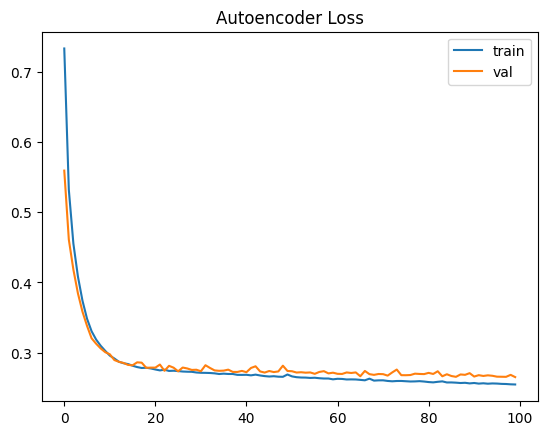

In [12]:
plt.plot(training.history['loss'], label='train')
plt.plot(training.history['val_loss'], label='val')
plt.legend()
plt.title("Autoencoder Loss")
plt.show()

In [11]:
# --- final compresses audio embeddings with 32 dim ---

compress_audio_embeddings = autoencoder.encoder.predict(audio_embed_train)
print(compress_audio_embeddings.shape)

362/362 ━━━━━━━━━━━━━━━━━━━━ 0s 559us/step
(11571, 32)


## 3. Visualization and Analysis

### **Wordcloud**
Analyzing in wordclouds the most frequent words used in the tags of **rap** and **rock** songs.

In [ ]:
from wordcloud import WordCloud


def create_wordcloud(text, title, color='white'):

    wordcloud = WordCloud(width=800, height=400, background_color=color).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

In [10]:
# Preparing the data for word cloud generation
wordcloud_df = data[['genres','tags']]
rap_df = wordcloud_df[wordcloud_df['genres'] == 'rap']
rock_df = wordcloud_df[wordcloud_df['genres'] == 'rock'] 

rap_tags = " ".join(rap_df['tags'].dropna())
rock_tags = " ".join(rock_df['tags'].dropna())

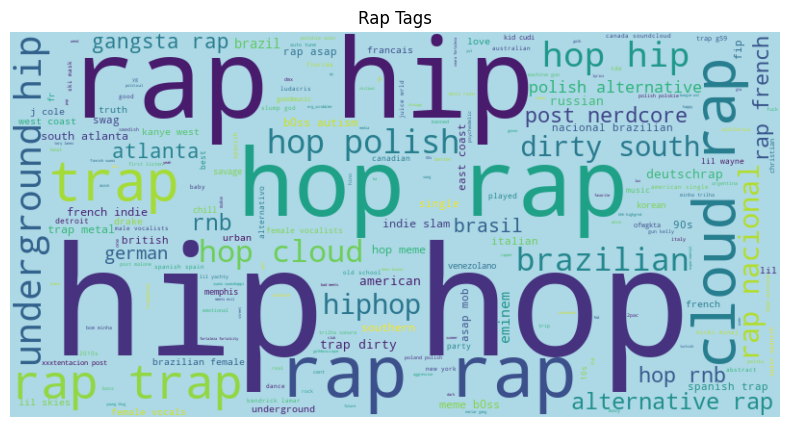

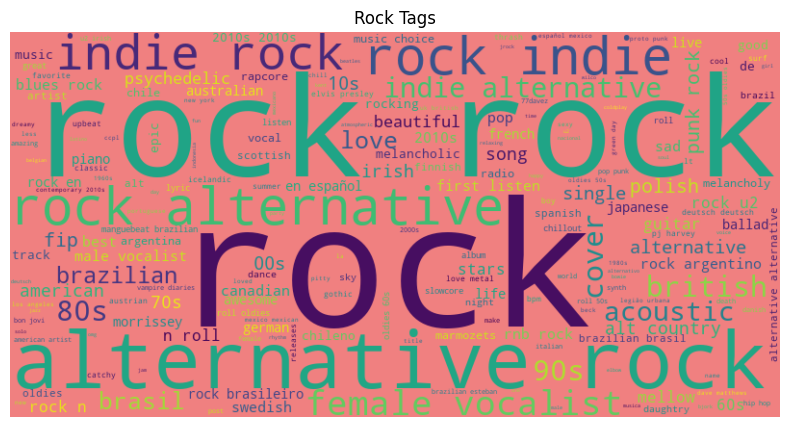

In [11]:
# Creating wordclouds for rap and rock genres
create_wordcloud(rap_tags, 'Rap Tags', color='lightblue')
create_wordcloud(rock_tags, 'Rock Tags', color='lightcoral')
